In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
import calendar
from scipy.stats import chi2_contingency
from tqdm import tqdm
from IPython.display import display, HTML

In [3]:
# Remove max-height restriction on output cells
display(HTML("<style>.jp-OutputArea-output { max-height: none !important; }</style>"))

In [4]:
df = pd.read_csv("./Dataframes/processed_data.csv", encoding="utf-8", parse_dates=["timestamp", "MESS_DATUM", "timestamp_berlin"], index_col = 'timestamp')

In [5]:
df.head()

,source_file,altitude,cadence,enhanced_speed,heart_rate,position_lat,position_long,power,target_power,MESS_DATUM,TM_10,timestamp_berlin,day_of_week,month,hour_utc,hour_berlin,time_of_day
timestamp,,,,,,,,,,,,,,,,,
2026-01-10 12:33:03+00:00,2026-01-10-13-32-12.fit,5.0,45,0.930,NaN,-138857456,1991775616,43,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:03+01:00,Saturday,January,12,13,Afternoon
2026-01-10 12:33:04+00:00,2026-01-10-13-32-12.fit,5.0,45,1.015,NaN,-138857440,1991775616,43,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:04+01:00,Saturday,January,12,13,Afternoon
2026-01-10 12:33:05+00:00,2026-01-10-13-32-12.fit,5.0,50,1.549,NaN,-138857312,1991775616,45,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:05+01:00,Saturday,January,12,13,Afternoon
2026-01-10 12:33:06+00:00,2026-01-10-13-32-12.fit,5.0,52,2.009,NaN,-138857104,1991775744,49,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:06+01:00,Saturday,January,12,13,Afternoon
2026-01-10 12:33:07+00:00,2026-01-10-13-32-12.fit,4.8,53,2.398,NaN,-138856880,1991775744,50,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:07+01:00,Saturday,January,12,13,Afternoon


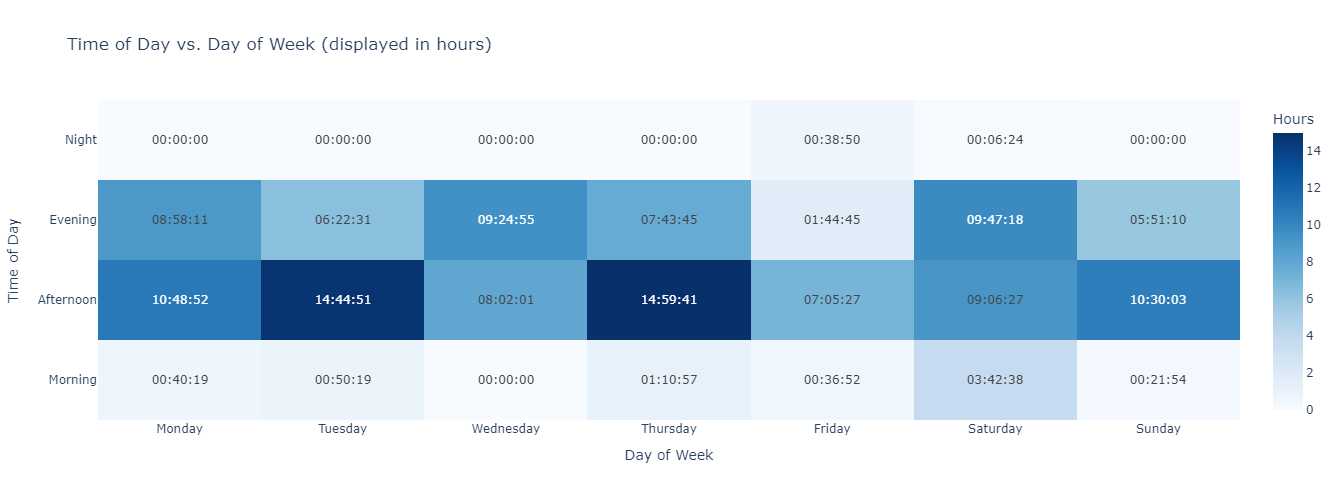

In [6]:
# Define order for consistent axis display
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
time_order = ["Morning", "Afternoon", "Evening", "Night"]

# Build contingency table (counts)
contingency_table = pd.crosstab(df["time_of_day"], df["day_of_week"])
contingency_table = contingency_table.reindex(index=time_order, columns=day_order)

# Convert counts to hours for display only
hours_table = contingency_table / 3600

def seconds_to_hms(total_seconds: int) -> str:
    """Convert a number of seconds into an HH:MM:SS formatted string.

    Args:
        total_seconds: Total duration in seconds.

    Returns:
        Formatted string as "HH:MM:SS".
    """
    total_seconds = int(total_seconds)
    hours, remainder = divmod(total_seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    return f"{hours:02d}:{minutes:02d}:{seconds:02d}"

text_labels = contingency_table.map(seconds_to_hms)

fig = go.Figure(
    data=go.Heatmap(
        z=hours_table.values,
        x=contingency_table.columns,
        y=contingency_table.index,
        colorscale="Blues",
        text=text_labels.values,
        texttemplate="%{text}",
        colorbar=dict(title="Hours"),
    )
)

fig.update_layout(
    title="Time of Day vs. Day of Week (displayed in hours)",
    xaxis_title="Day of Week",
    yaxis_title="Time of Day",
    width=800,
    height=500,
)
fig.show()

In [7]:
def get_best_average(
    df: pd.DataFrame,
    metric: str,
    duration_seconds: int,
) -> float:
    """Find the highest rolling average of a metric over a given duration.

    Windows that span a gap in the index (missing timestamps) are
    excluded from the evaluation, since a full second-by-second index
    is assumed but not guaranteed to be complete.

    Args:
        df: DataFrame with a DatetimeIndex (one row per second) containing
            at least the column specified by `metric`.
        metric: Column name to analyze, e.g. "heart_rate" or "power".
        duration_seconds: Length of the rolling window in seconds.

    Returns:
        The highest average value of the metric over any window of the
        given duration.

    Raises:
        ValueError: If the metric column does not exist or no valid
            window could be found.
    """
    if metric not in df.columns:
        raise ValueError(f"Column '{metric}' not found in dataframe.")

    series = df[metric]

    # Reindex to a complete second-by-second range so gaps become NaN
    full_index = pd.date_range(
        start=series.index.min(), end=series.index.max(), freq="1s"
    )
    reindexed = series.reindex(full_index)

    # min_periods=duration_seconds ensures windows with any NaN are dropped
    rolling_avg = reindexed.rolling(
        window=duration_seconds, min_periods=duration_seconds
    ).mean()

    best_avg = rolling_avg.max()

    if pd.isna(best_avg):
        raise ValueError(
            f"No valid {duration_seconds}-second window found for '{metric}'."
        )

    return best_avg

In [8]:
get_best_average(df, 'heart_rate', 60)

np.float64(198.31666666666666)

In [9]:
get_best_average(df, 'power', 60)

np.float64(380.28333333333336)

In [14]:
df.heart_rate.max

<bound method Series.max of timestamp
2026-01-10 12:33:03+00:00      NaN
2026-01-10 12:33:04+00:00      NaN
2026-01-10 12:33:05+00:00      NaN
2026-01-10 12:33:06+00:00      NaN
2026-01-10 12:33:07+00:00      NaN
                             ...  
2026-08-04 15:55:39+00:00    123.0
2026-08-04 15:55:40+00:00    123.0
2026-08-04 15:55:41+00:00    123.0
2026-08-04 15:55:42+00:00    124.0
2026-08-04 15:55:43+00:00    124.0
Name: heart_rate, Length: 479890, dtype: float64>

In [ ]:
Die höchste Herzfrequenz über eine Minute liegt also nur knapp unter der maximalen Herzfrequenz.

In [16]:
def _format_duration_label(seconds: int) -> str:
    """Format a duration in seconds as a human-readable label.

    Args:
        seconds: Duration in seconds.

    Returns:
        A short label like "30s", "5m", "1h 30m".
    """
    if seconds < 60:
        return f"{seconds}s"
    minutes, remaining_seconds = divmod(seconds, 60)
    if minutes < 60:
        return f"{minutes}m" if remaining_seconds == 0 else f"{minutes}m{remaining_seconds}s"
    hours, remaining_minutes = divmod(minutes, 60)
    return f"{hours}h" if remaining_minutes == 0 else f"{hours}h{remaining_minutes}m"

def _compute_best_averages_vectorized(
    values: np.ndarray,
    durations: np.ndarray,
    show_progress: bool = True,
) -> np.ndarray:
    """Compute the best rolling average for each duration using vectorized ops.

    Uses the cumulative-sum trick to get windowed sums in O(n) per duration
    instead of relying on pandas rolling in a Python loop. NaNs (gaps in
    the original data) are propagated so windows spanning a gap are
    correctly excluded.

    Args:
        values: 1D array of metric values (may contain NaN for gaps).
        durations: 1D array of window sizes (in samples) to evaluate.

    Returns:
        1D array of best average values, one per duration. NaN if no valid
        window exists for that duration.
    """
    n = len(values)
    # Cumulative sum with a leading zero for O(1) windowed-sum lookups.
    # NaNs must be handled separately since np.cumsum propagates them.
    is_nan = np.isnan(values)
    clean_values = np.where(is_nan, 0.0, values)
    cumsum = np.concatenate([[0.0], np.cumsum(clean_values)])
    cumsum_nan_count = np.concatenate([[0], np.cumsum(is_nan.astype(int))])

    best_averages = np.full(len(durations), np.nan)

    iterator = (
        tqdm(enumerate(durations), total=len(durations), desc="Computing durations")
        if show_progress
        else enumerate(durations)
    )

    for idx, window in iterator:
        window = int(window)
        if window > n:
            continue

        window_sums = cumsum[window:] - cumsum[:-window]
        window_nan_counts = cumsum_nan_count[window:] - cumsum_nan_count[:-window]

        # Only consider windows without any NaN (i.e. no gap in the data)
        valid_mask = window_nan_counts == 0
        if not np.any(valid_mask):
            continue

        window_means = window_sums[valid_mask] / window
        best_averages[idx] = window_means.max()

    return best_averages


def build_duration_curve_data(
    df: pd.DataFrame,
    metric: str,
    min_duration: int = 1,
    max_duration: int | None = None,
) -> pd.DataFrame:
    """Compute best-average values across a log-spaced range of durations.

    Args:
        df: DataFrame with a DatetimeIndex (one row per second) containing
            at least the column specified by `metric`.
        metric: Column name to analyze, e.g. "heart_rate" or "power".
        min_duration: Shortest window duration in seconds.
        max_duration: Longest window duration in seconds. Defaults to the
            total duration of the dataframe in seconds.

    Returns:
        A DataFrame with columns "duration_seconds" and "best_value",
        sorted by duration.
    """
    if max_duration is None:
        max_duration = min(int((df.index.max() - df.index.min()).total_seconds()), 2 * 3600)

    series = df[metric]
    full_index = pd.date_range(
        start=series.index.min(), end=series.index.max(), freq="1s"
    )
    reindexed = series.reindex(full_index)
    values = reindexed.to_numpy(dtype=float)

    durations = np.arange(min_duration, max_duration + 1)
    best_values = _compute_best_averages_vectorized(values, durations, show_progress=True)

    valid_mask = ~np.isnan(best_values)
    return pd.DataFrame(
        {
            "duration_seconds": durations[valid_mask],
            "best_value": best_values[valid_mask],
        }
    )


def plot_duration_curve(
    df: pd.DataFrame,
    metric: str,
    min_duration: int = 1,
    max_duration: int | None = None,
    x_axis_exponent: float = 0.6,
) -> go.Figure:
    """Plot an interactive duration curve (best average vs. window duration).

    Uses a logarithmic x-axis so short durations are shown with high
    resolution while long durations remain readable without excessive
    granularity.

    Args:
        df: DataFrame with a DatetimeIndex (one row per second) containing
            at least the column specified by `metric`.
        metric: Column name to analyze, e.g. "heart_rate" or "power".
        min_duration: Shortest window duration in seconds.
        max_duration: Longest window duration in seconds. Defaults to the
            total duration of the dataframe in seconds.

    Returns:
        A Plotly Figure object.
    """
    curve_data = build_duration_curve_data(df, metric, min_duration, max_duration)
    curve_data["duration_label"] = curve_data["duration_seconds"].apply(
        _format_duration_label
    )

    
    transformed_x = curve_data["duration_seconds"] ** x_axis_exponent

    metric_label = "Heart Rate (bpm)" if metric == "heart_rate" else "Power (W)"
    title_label = "Heart Rate" if metric == "heart_rate" else "Power"
    line_color = "#d62728" if metric == "heart_rate" else "#1f77b4"
    fill_color = (
        "rgba(214, 39, 40, 0.15)" if metric == "heart_rate" else "rgba(31, 119, 180, 0.15)"
    )

    fig = go.Figure(
        data=go.Scatter(
            x=transformed_x,
            y=curve_data["best_value"],
            mode="lines",
            line=dict(color=line_color, width=2.5, shape="spline"),
            fill="tozeroy",
            fillcolor=fill_color,
            customdata=curve_data["duration_label"],
            hovertemplate=(
                "Duration: %{customdata}<br>"
                f"Best {title_label}: " + "%{y:.1f}<extra></extra>"
            ),
        )
    )

    max_seconds = int(curve_data["duration_seconds"].max())
    tick_candidates = [1, 5, 10, 15, 30, 60, 120, 300, 600, 900, 1200, 1800, 2700, 3600, 5400, 7200]
    tick_seconds = [t for t in tick_candidates if t <= max_seconds] or [max_seconds]
    tick_values = [t ** x_axis_exponent for t in tick_seconds]
    tick_labels = [_format_duration_label(t) for t in tick_seconds]

    fig.update_layout(
        title=f"{title_label} Duration Curve",
        xaxis_title="Duration",
        yaxis_title=f"Best average {metric_label}",
        template="plotly_white",
        hovermode="closest",
        height=800,
    )

    fig.update_xaxes(
        type="linear",
        tickmode="array",
        tickvals=tick_values,
        ticktext=tick_labels,
    )
    fig.update_yaxes(rangemode="tozero")

    return fig

Computing durations: 100%|██████████| 7200/7200 [09:36<00:00, 12.50it/s]


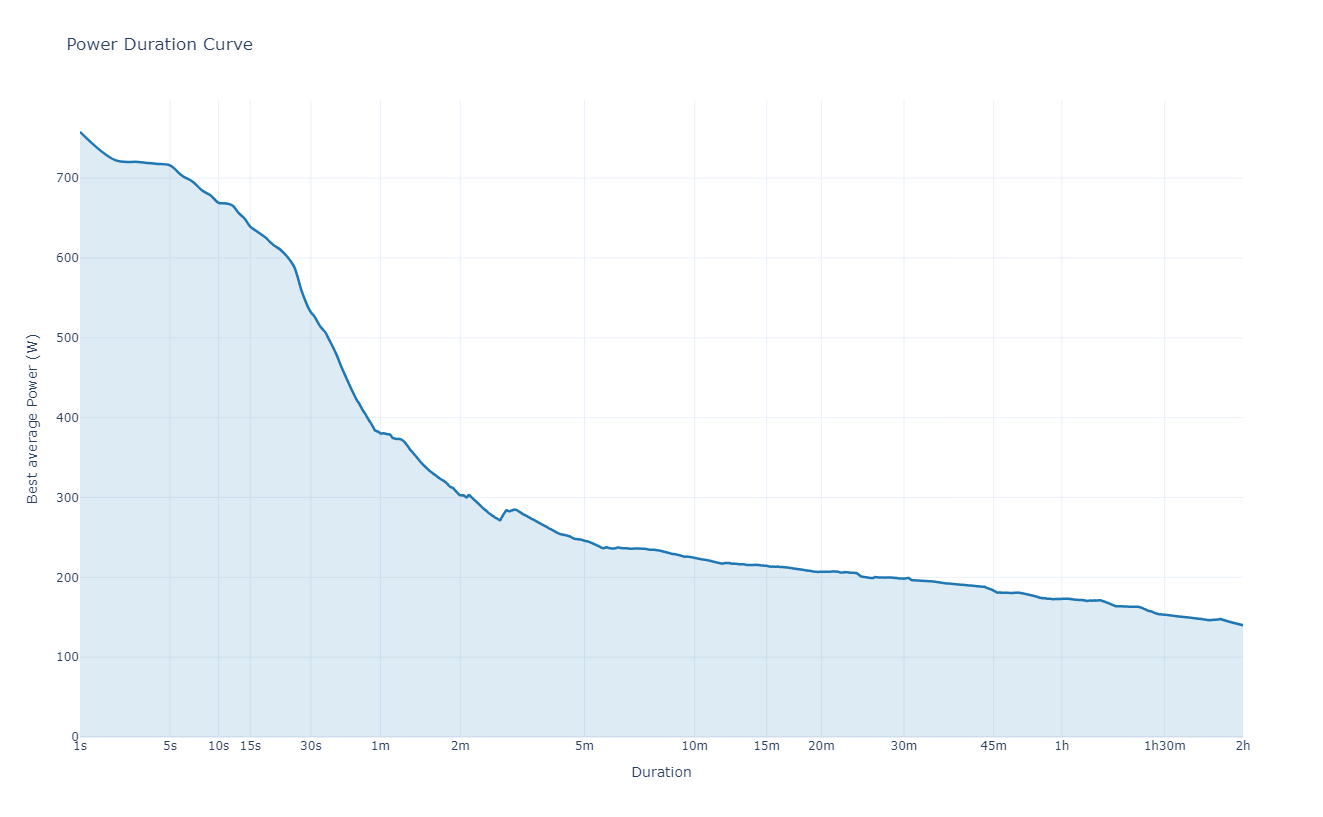

In [11]:
fig = plot_duration_curve(df, metric="power", max_duration=60*60*2, x_axis_exponent = 0.2)
fig.show()

In [15]:
def plot_duration_curve_by_month(
    df: pd.DataFrame,
    metric: str,
    months: range,
    min_duration: int = 1,
    max_duration: int | None = None,
    x_axis_exponent: float = 0.6,
    colorscale: str = "Turbo",
    line_width: float = 2.0,
    line_opacity: float = 0.85,
    alternate_dash: bool = True,
) -> go.Figure:
    """Plot duration curves for multiple months in a single figure.

    Earlier months are rendered in colors from one end of the given
    colorscale, later months from the other end. To keep many overlapping
    curves distinguishable, line opacity is reduced and (optionally)
    alternating line styles are used in addition to color.

    Args:
        df: DataFrame with a 'month' column containing English month names
            (e.g. "January"), plus at least the column specified by `metric`.
        metric: Column name to analyze, e.g. "heart_rate" or "power".
        months: Iterable of month numbers to include (1 = January, ...,
            12 = December).
        min_duration: Shortest window duration in seconds.
        max_duration: Longest window duration in seconds.
        x_axis_exponent: Exponent used for the x-axis scaling.
        colorscale: Plotly colorscale name used for the month color coding.
        line_width: Width of each duration curve line.
        line_opacity: Opacity of each duration curve line (0-1).
        alternate_dash: If True, alternate between solid and dashed lines
            to further distinguish neighboring months.

    Returns:
        A Plotly Figure containing one duration curve per month, with a
        hover label that includes the month name.
    """
    months = list(months)
    colors = px.colors.sample_colorscale(
        colorscale, [i / max(len(months) - 1, 1) for i in range(len(months))]
    )
    dash_styles = ["solid", "dash"]

    month_names = list(calendar.month_name)

    fig = go.Figure()
    month_fig = None

    for i, (month, color) in enumerate(zip(months, colors)):
        month_name = month_names[month]
        df_month = df[df["month"] == month_name]

        if df_month.empty:
            continue

        month_fig = plot_duration_curve(
            df_month,
            metric=metric,
            min_duration=min_duration,
            max_duration=max_duration,
            x_axis_exponent=x_axis_exponent,
        )

        dash = dash_styles[i % 2] if alternate_dash else "solid"

        trace = month_fig.data[0]
        trace.update(
            line=dict(color=color, width=line_width, dash=dash, shape="spline"),
            opacity=line_opacity,
            fill=None,
            name=month_name,
            showlegend=True,
            hovertemplate=(
                f"<b>{month_name}</b><br>"
                "Duration: %{x}<br>"
                "Value: %{y:.0f}<extra></extra>"
            ),
        )
        fig.add_trace(trace)

    if month_fig is not None:
        fig.update_layout(month_fig.layout)
        fig.update_layout(
            title=f"{month_fig.layout.title.text} by Month",
            legend_title="Month",
            hovermode="closest",
        )

    return fig

Computing durations: 100%|██████████| 7200/7200 [00:08<00:00, 872.01it/s]


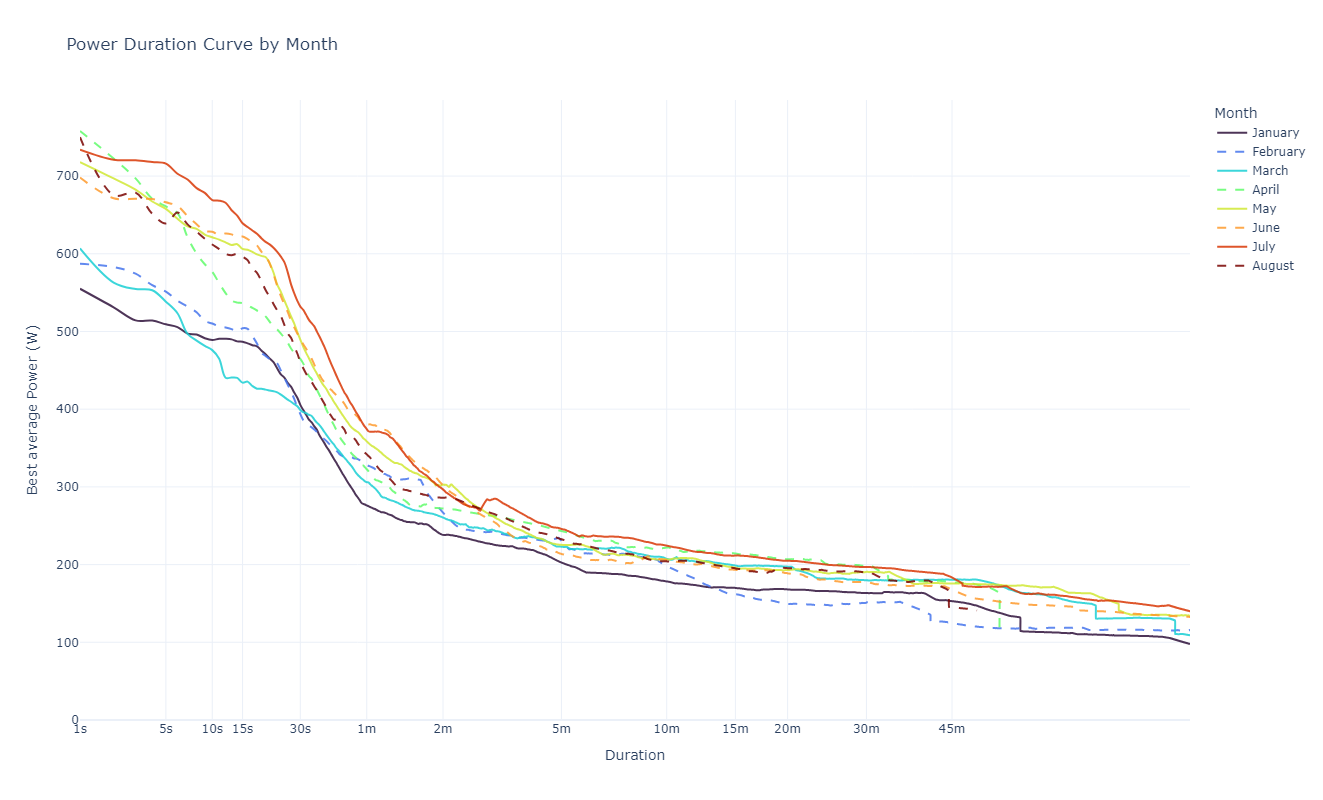

In [13]:
fig = plot_duration_curve_by_month(
    df,
    metric="power",
    months=range(1,9),
    max_duration=60*60*2,
    x_axis_exponent=0.2,
    colorscale="Turbo",
    line_opacity=0.85,
    alternate_dash=True,
)
fig.show()

Die Power Duration Curves zeigen eine klare, kontinuierliche Leistungssteigerung von <span style="color:#30123b">**Januar**</span> bis <span style="color:#d93806">**Juli**</span> über nahezu alle Belastungsdauern hinweg. Dieser Trend deutet auf eine erfolgreiche Trainingsprogression über den betrachteten Zeitraum hin.

Der sichtbare Leistungsabfall im <span style="color:#7a0402">**August**</span> ist dagegen nicht auf einen Fitnessverlust im eigentlichen Sinne zurückzuführen, sondern lässt sich durch zwei externe Faktoren erklären:

    Verletzung im Juli: Eine Verletzung führte zu einer erzwungenen Trainingsunterbrechung.
    Geringe Datenbasis im August: Aufgrund eingeschränkter Zeitverfügbarkeit gab es nur sehr wenige Fahrten in diesem Monat. Die Power Duration Curve basiert dadurch auf einer deutlich kleineren Stichprobe, was insbesondere für längere Belastungsdauern zu einer unzureichenden Datengrundlage führt. Die dargestellte Kurve ist somit statistisch weniger belastbar und bildet vermutlich nicht das tatsächliche Leistungsniveau ab.

Der Rückgang im August ist somit im Kontext dieser Rahmenbedingungen zu bewerten und nicht als Indikator für einen Leistungsabfall zu interpretieren, sondern als Folge von verletzungsbedingter Pause und einer zu geringen Datenbasis für eine belastbare Aussage. Die grundsätzliche Aufwärtsentwicklung von Januar bis Juli bleibt davon unberührt und bildet die relevante Baseline für die weitere Trainingsplanung.

Computing durations: 100%|██████████| 7200/7200 [09:30<00:00, 12.61it/s]


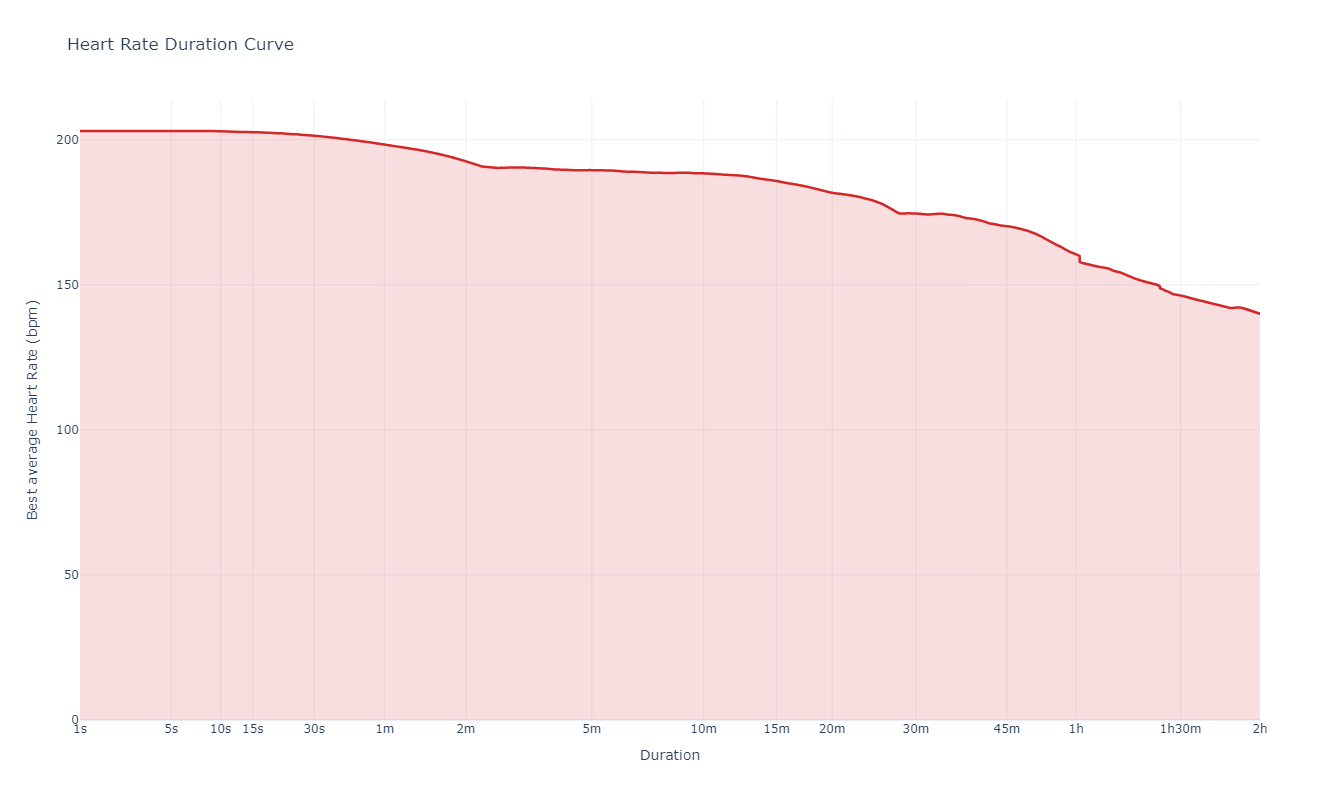

In [17]:
fig = plot_duration_curve(df, metric="heart_rate", max_duration=60*60*2, x_axis_exponent = 0.2)
fig.show()

Computing durations: 100%|██████████| 7200/7200 [00:08<00:00, 843.19it/s]


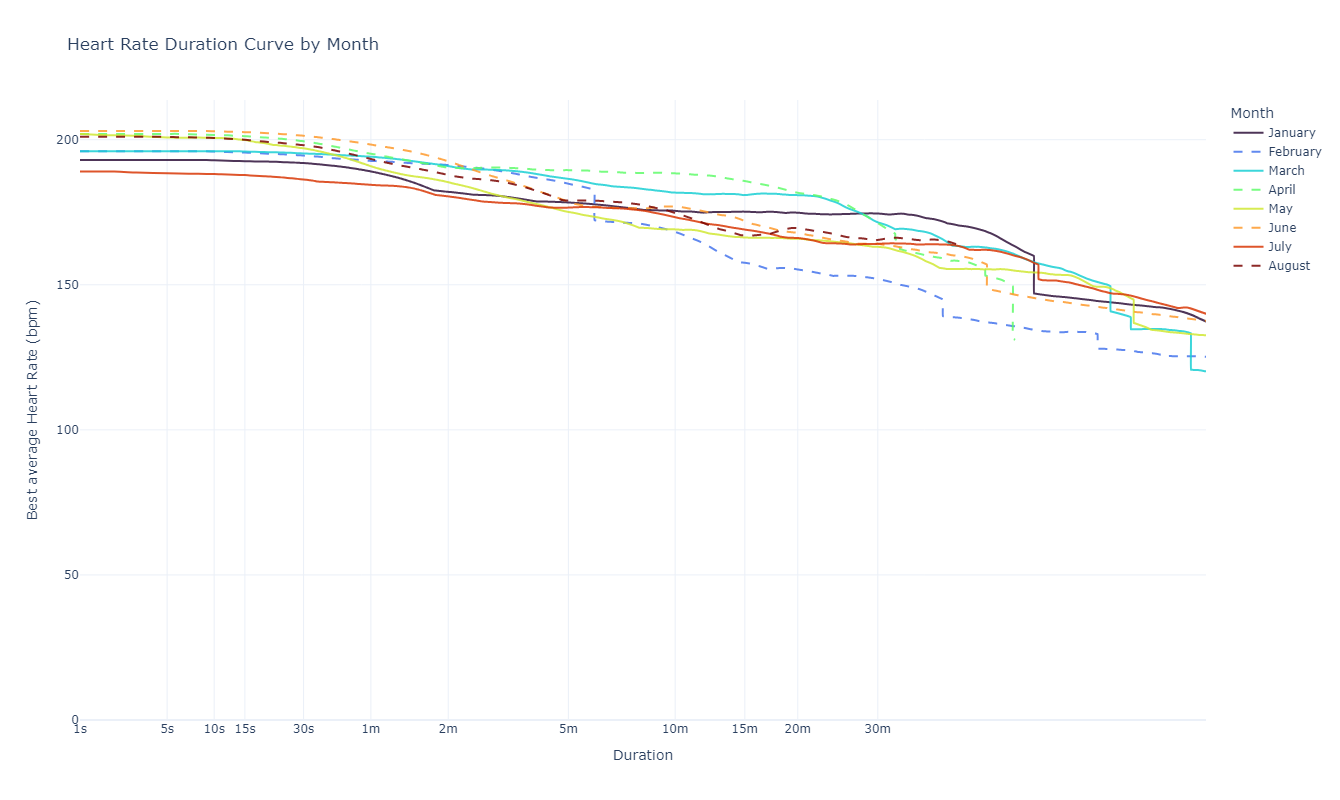

In [18]:
fig = plot_duration_curve_by_month(
    df,
    metric="heart_rate",
    months=range(1,9),
    max_duration=60*60*2,
    x_axis_exponent=0.2,
    colorscale="Turbo",
    line_opacity=0.85,
    alternate_dash=True,
)
fig.show()

In [19]:
def compute_cross_correlation(
    power: pd.Series,
    heart_rate: pd.Series,
    max_lag: int = 20,
) -> pd.DataFrame:
    """Compute cross-correlation between power and heart rate for a range of lags.

    For each lag tau, computes corr(power(t), heart_rate(t + tau)),
    i.e. heart rate is shifted backwards to test if it lags behind power.

    Args:
        power: Time series of power values (one entry per second).
        heart_rate: Time series of heart rate values (one entry per second).
        max_lag: Maximum lag in seconds to test (tested from 0 to max_lag).

    Returns:
        DataFrame with columns 'lag' and 'correlation'.
    """
    results = []

    for lag in range(0, max_lag + 1):
        shifted_hr = heart_rate.shift(-lag)

        valid_mask = shifted_hr.notna() & power.notna()
        correlation = power[valid_mask].corr(shifted_hr[valid_mask])

        results.append({"lag": lag, "correlation": correlation})

    return pd.DataFrame(results)


def compute_cross_correlation_per_ride(
    df: pd.DataFrame,
    ride_id_col: str = "ride_id",
    power_col: str = "power",
    heart_rate_col: str = "heart_rate",
    max_lag: int = 20,
) -> pd.DataFrame:
    """Compute cross-correlation separately for each ride.

    Args:
        df: DataFrame containing multiple rides, one row per second.
        ride_id_col: Column name identifying individual rides.
        power_col: Column name for power values.
        heart_rate_col: Column name for heart rate values.
        max_lag: Maximum lag in seconds to test.

    Returns:
        DataFrame with columns 'ride_id', 'lag' and 'correlation',
        containing one cross-correlation curve per ride.
    """
    all_results = []

    for ride_id, group in df.groupby(ride_id_col):
        corr_df = compute_cross_correlation(
            power=group[power_col],
            heart_rate=group[heart_rate_col],
            max_lag=max_lag,
        )
        corr_df["ride_id"] = ride_id
        all_results.append(corr_df)

    return pd.concat(all_results, ignore_index=True)


def average_cross_correlation(per_ride_df: pd.DataFrame) -> pd.DataFrame:
    """Average cross-correlation curves across all rides.

    Args:
        per_ride_df: DataFrame with columns 'ride_id', 'lag', 'correlation'.

    Returns:
        DataFrame with columns 'lag', 'mean_correlation', 'std_correlation'.
    """
    averaged = (
        per_ride_df.groupby("lag")["correlation"]
        .agg(mean_correlation="mean", std_correlation="std")
        .reset_index()
    )
    return averaged


def find_best_lag(averaged_df: pd.DataFrame) -> int:
    """Return the lag with the highest average correlation.

    Args:
        averaged_df: DataFrame with columns 'lag' and 'mean_correlation'.

    Returns:
        The lag (in seconds) with the maximum average correlation.
    """
    best_row = averaged_df.loc[averaged_df["mean_correlation"].idxmax()]
    return int(best_row["lag"])


def plot_cross_correlation_overview(
    per_ride_df: pd.DataFrame,
    averaged_df: pd.DataFrame,
    best_lag: int,
) -> go.Figure:
    """Plot per-ride cross-correlation curves plus the averaged curve.

    Args:
        per_ride_df: DataFrame with columns 'ride_id', 'lag', 'correlation'.
        averaged_df: DataFrame with columns 'lag', 'mean_correlation', 'std_correlation'.
        best_lag: The lag with the highest average correlation.

    Returns:
        Plotly figure object.
    """
    fig = go.Figure()

    # Individual ride curves (light, transparent)
    for ride_id, group in per_ride_df.groupby("ride_id"):
        fig.add_trace(
            go.Scatter(
                x=group["lag"],
                y=group["correlation"],
                mode="lines",
                name=f"Ride {ride_id}",
                line=dict(width=1),
                opacity=0.3,
                showlegend=False,
            )
        )

    # Confidence band (mean +/- std)
    fig.add_trace(
        go.Scatter(
            x=pd.concat([averaged_df["lag"], averaged_df["lag"][::-1]]),
            y=pd.concat(
                [
                    averaged_df["mean_correlation"] + averaged_df["std_correlation"],
                    (averaged_df["mean_correlation"] - averaged_df["std_correlation"])[::-1],
                ]
            ),
            fill="toself",
            fillcolor="rgba(0,0,0,0.1)",
            line=dict(color="rgba(255,255,255,0)"),
            hoverinfo="skip",
            name="±1 std",
        )
    )

    # Average curve (bold)
    fig.add_trace(
        go.Scatter(
            x=averaged_df["lag"],
            y=averaged_df["mean_correlation"],
            mode="lines+markers",
            name="Average correlation",
            line=dict(color="black", width=3),
            marker=dict(size=6),
        )
    )

    # Highlight best lag
    best_value = averaged_df.loc[
        averaged_df["lag"] == best_lag, "mean_correlation"
    ].values[0]

    fig.add_vline(
        x=best_lag,
        line_dash="dash",
        line_color="red",
        annotation_text=f"Best lag = {best_lag}s",
        annotation_position="top right",
    )

    fig.add_trace(
        go.Scatter(
            x=[best_lag],
            y=[best_value],
            mode="markers",
            marker=dict(size=12, color="red", symbol="star"),
            name=f"Best lag ({best_lag}s)",
        )
    )

    fig.update_layout(
        title="Cross-Correlation: Power vs Heart Rate (averaged over rides)",
        xaxis_title="Lag (seconds)",
        yaxis_title="Correlation",
        template="plotly_white",
        hovermode="x unified",
    )

    return fig

Best lag averaged over all rides: 29 seconds


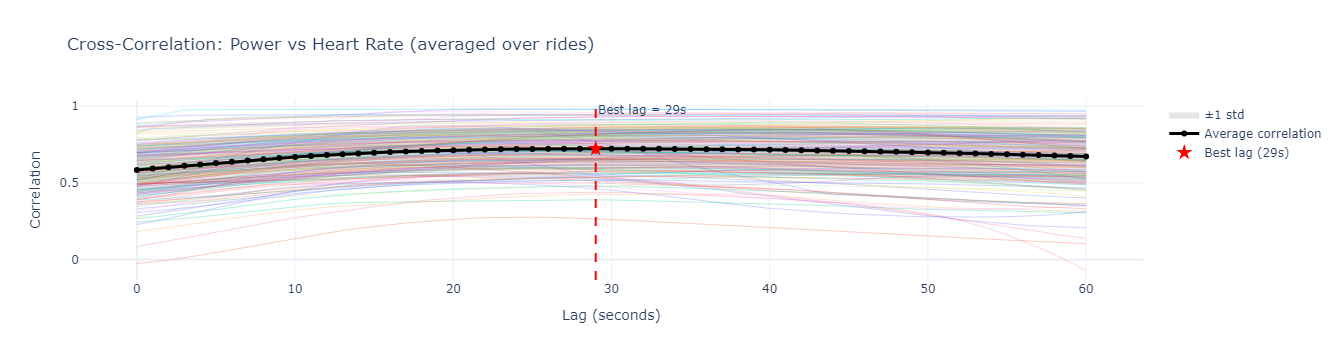

In [24]:
per_ride_df = compute_cross_correlation_per_ride(
    df,
    ride_id_col="source_file",
    power_col="power",
    heart_rate_col="heart_rate",
    max_lag=60,
)

per_ride_df = per_ride_df.dropna(subset=["correlation"])

averaged_df = average_cross_correlation(per_ride_df)

best_lag = find_best_lag(averaged_df)
print(f"Best lag averaged over all rides: {best_lag} seconds")

fig = plot_cross_correlation_overview(per_ride_df, averaged_df, best_lag)
fig.show()

In [25]:
per_ride_df.sample(5)

,lag,correlation,ride_id
8570,30,0.776155,2026-06-22-20-00-29.fit
3615,16,0.810472,2026-03-11-20-25-25.fit
1330,49,0.673476,2026-01-29-12-45-53.fit
7565,1,0.276211,2026-05-23-17-54-45.fit
1575,50,0.554695,2026-02-02-18-11-54.fit


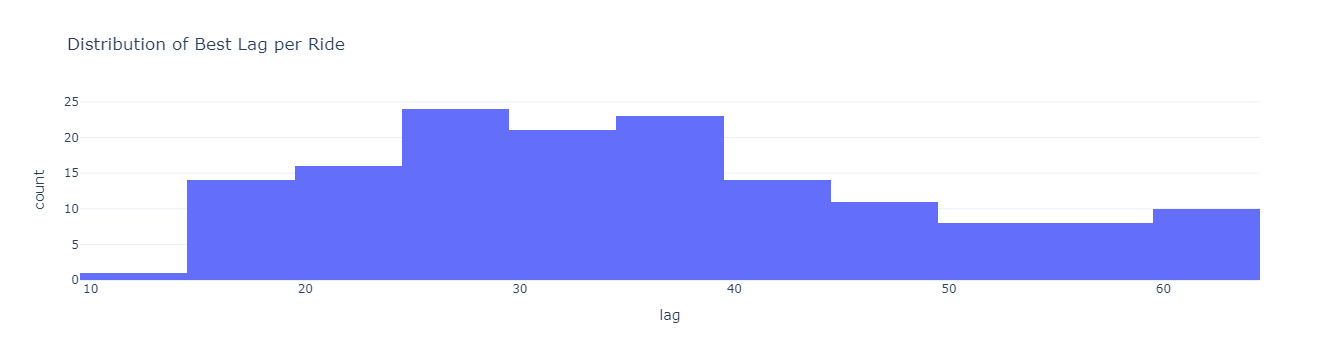

In [27]:
idx = per_ride_df.groupby("ride_id")["correlation"].idxmax()
best_per_ride_df = per_ride_df.loc[idx].reset_index(drop=True)

fig = px.histogram(
    best_per_ride_df,
    x="lag",
    title="Distribution of Best Lag per Ride",
    template="plotly_white",
)
fig.show()

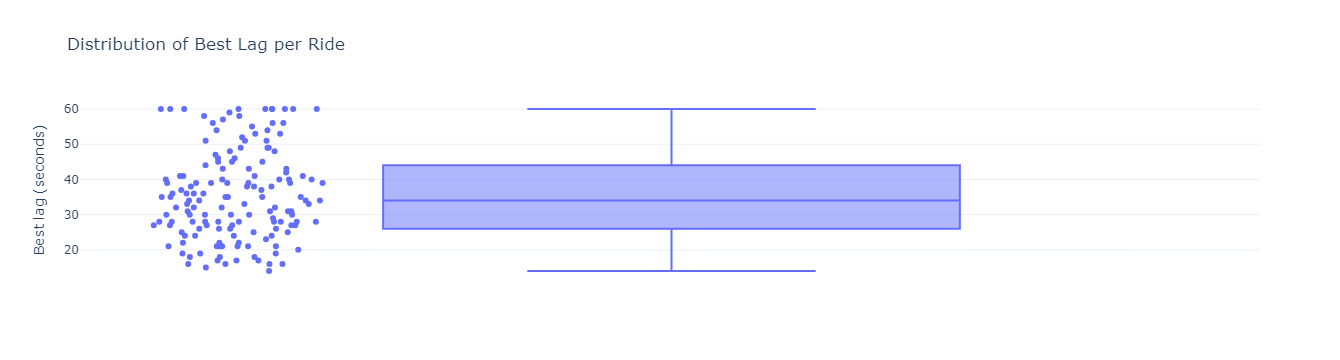

In [29]:
fig = px.box(
        best_per_ride_df,
        y="lag",
        points="all",
        title="Distribution of Best Lag per Ride",
        template="plotly_white",
    )
fig.update_layout(yaxis_title="Best lag (seconds)")
fig.show()

In [59]:
def compute_power_zone(
    df: pd.DataFrame,
    ftp: float,
    power_col: str = "power",
    zone_col: str = "power_zone",
) -> pd.DataFrame:
    """Assign a power zone label to each row based on power relative to FTP.

    Uses the standard 7-zone model (percentage of FTP):
        Zone 1 (Active Recovery): < 55%
        Zone 2 (Endurance): 55-75%
        Zone 3 (Tempo): 75-90%
        Zone 4 (Threshold): 90-105%
        Zone 5 (VO2 Max): 105-120%
        Zone 6 (Anaerobic Capacity): 120-150%
        Zone 7 (Neuromuscular): > 150%

    Args:
        df: DataFrame containing power_col.
        ftp: Functional Threshold Power, used as the reference for zone boundaries.
        power_col: Column name containing power values in watts.
        zone_col: Name of the output column to store the zone label.

    Returns:
        DataFrame with an added zone_col containing integer zone labels (1-7).
    """
    df = df.copy()
    pct_ftp = df[power_col] / ftp * 100

    bins = [-np.inf, 55, 75, 90, 105, 120, 150, np.inf]
    labels = [1, 2, 3, 4, 5, 6, 7]

    df[zone_col] = pd.cut(pct_ftp, bins=bins, labels=labels).astype(int)
    return df

In [62]:
def identify_transitions_with_fixed_lookahead(
    df: pd.DataFrame,
    zone_col: str = "power_zone",
    ride_id_col: str = "source_file",
    lookahead: int = 90,
) -> pd.DataFrame:
    """Extract windows starting at each zone transition with a fixed lookahead period.

    Each window is capped at the start of the next transition within the same ride,
    preventing overlap and contamination from the following zone's power values.

    Args:
        df: DataFrame with ride_id_col, 'timestamp', zone_col, ordered by time.
        zone_col: Column name containing the power zone label.
        ride_id_col: Column name identifying each individual ride.
        lookahead: Number of seconds to include after the transition (fixed,
            but capped if the next transition occurs sooner).

    Returns:
        DataFrame with an added 'transition_id' column and 'target_zone' column,
        containing samples from the transition point up to `lookahead` seconds
        after it, or up to the next transition, whichever comes first.
    """
    df = df.sort_values([ride_id_col, "timestamp"]).reset_index(drop=True)

    same_ride = df[ride_id_col] == df[ride_id_col].shift()
    zone_changed = (df[zone_col] != df[zone_col].shift()) & same_ride
    transition_positions = df.index[zone_changed]

    windows = []
    for i, pos in enumerate(transition_positions):
        ride_id = df.loc[pos, ride_id_col]
        target_zone = df.loc[pos, zone_col]
        transition_time = df.loc[pos, "timestamp"]

        ride_positions = df.index[df[ride_id_col] == ride_id]
        max_end_by_lookahead = pos + lookahead

        # Cap the window at the next transition within the same ride, if any
        next_transition_in_ride = [
            p for p in transition_positions[i + 1:]
            if p in ride_positions
        ]
        max_end_by_next_transition = next_transition_in_ride[0] - 1 if next_transition_in_ride else None

        candidates = [max_end_by_lookahead, ride_positions.max()]
        if max_end_by_next_transition is not None:
            candidates.append(max_end_by_next_transition)
        end = min(candidates)

        window_df = df.loc[pos:end].copy()
        window_df["transition_id"] = i
        window_df["target_zone"] = target_zone
        window_df["seconds_from_transition"] = (
            window_df["timestamp"] - transition_time
        ).dt.total_seconds()
        windows.append(window_df)

    return pd.concat(windows, ignore_index=True) if windows else df.iloc[0:0]


def filter_transitions_by_min_lookahead(
    df: pd.DataFrame, required_lookahead: int, transition_id_col: str = "transition_id"
) -> pd.DataFrame:
    """Discard transitions that got cut off before reaching the required lookahead.

    This happens when a transition occurs near the end of a ride, so there is
    not enough data after it to reliably capture the delayed heart rate response.

    Args:
        df: DataFrame with transition_id_col and 'seconds_from_transition'.
        required_lookahead: Minimum number of seconds after the transition that
            must be present in the window.
        transition_id_col: Column identifying each transition window.

    Returns:
        Filtered DataFrame containing only transitions with sufficient lookahead data.
    """
    max_offset_per_transition = df.groupby(transition_id_col)["seconds_from_transition"].max()
    valid_ids = max_offset_per_transition[max_offset_per_transition >= required_lookahead].index
    return df[df[transition_id_col].isin(valid_ids)]


def compute_cross_correlation(power: np.ndarray, heart_rate: np.ndarray, max_lag: int) -> pd.DataFrame:
    """Compute cross-correlation between power and heart rate for lags 0 to max_lag.

    Args:
        power: Power values, ordered by time.
        heart_rate: Heart rate values, ordered by time (same length as power).
        max_lag: Maximum lag (in samples) to test.

    Returns:
        DataFrame with columns 'lag' and 'correlation'.
    """
    results = []
    for lag in range(max_lag + 1):
        if lag == 0:
            shifted_hr, shifted_power = heart_rate, power
        else:
            shifted_hr = heart_rate[lag:]
            shifted_power = power[:-lag]
        correlation = np.corrcoef(shifted_power, shifted_hr)[0, 1] if len(shifted_power) >= 2 else np.nan
        results.append({"lag": lag, "correlation": correlation})
    return pd.DataFrame(results)


def compute_cross_correlation_per_transition(
    df: pd.DataFrame,
    max_lag: int,
    transition_id_col: str = "transition_id",
    ride_id_col: str = "source_file",
) -> pd.DataFrame:
    """Compute cross-correlation for every transition window independently.

    Args:
        df: DataFrame with transition_id_col, ride_id_col, 'target_zone', 'power', 'heart_rate'.
        max_lag: Maximum lag (in seconds) to test, fixed across all transitions.
        transition_id_col: Column identifying each transition window.
        ride_id_col: Column name identifying each individual ride.

    Returns:
        Long-format DataFrame with one row per (transition_id, lag) combination,
        including ride_id_col, 'target_zone'.
    """
    all_results = []
    for transition_id, window_df in df.groupby(transition_id_col):
        corr_df = compute_cross_correlation(
            window_df["power"].to_numpy(),
            window_df["heart_rate"].to_numpy(),
            max_lag=max_lag,
        )
        corr_df["transition_id"] = transition_id
        corr_df[ride_id_col] = window_df[ride_id_col].iloc[0]
        corr_df["target_zone"] = window_df["target_zone"].iloc[0]
        all_results.append(corr_df)

    return pd.concat(all_results, ignore_index=True)


def get_best_lag_per_transition(per_transition_df: pd.DataFrame) -> pd.DataFrame:
    """Extract the lag with maximum correlation for each transition window.

    Args:
        per_transition_df: Long-format DataFrame with 'transition_id', 'lag', 'correlation'.

    Returns:
        DataFrame with one row per transition, containing the best lag and its correlation.
    """
    valid_df = per_transition_df.dropna(subset=["correlation"])
    best_idx = valid_df.groupby("transition_id")["correlation"].idxmax()
    return valid_df.loc[best_idx].reset_index(drop=True)


def compute_time_to_hr_peak(
    df: pd.DataFrame, transition_id_col: str = "transition_id", hr_col: str = "heart_rate"
) -> pd.DataFrame:
    """Compute how many seconds after the transition the heart rate reaches its peak.

    Args:
        df: DataFrame with transition_id_col, 'seconds_from_transition', hr_col.
        transition_id_col: Column identifying each transition window.
        hr_col: Column name containing heart rate values.

    Returns:
        DataFrame with one row per transition, containing the time (in seconds
        relative to the transition) at which heart rate peaked within the window.
    """
    results = []
    for transition_id, window_df in df.groupby(transition_id_col):
        peak_idx = window_df[hr_col].idxmax()
        results.append({
            "transition_id": transition_id,
            "time_to_hr_peak": window_df.loc[peak_idx, "seconds_from_transition"],
            "peak_hr": window_df.loc[peak_idx, hr_col],
        })
    return pd.DataFrame(results)


def compute_hr_baseline(
    df: pd.DataFrame,
    zone_col: str = "power_zone",
    ride_id_col: str = "source_file",
    lookback: int = 15,
    hr_col: str = "heart_rate",
) -> pd.DataFrame:
    """Compute the mean heart rate just before each zone transition, as a baseline reference.

    This is kept separate from the correlation window, since mixing pre-transition
    data into the correlation would blend two different power levels together.

    Args:
        df: DataFrame with ride_id_col, 'timestamp', zone_col, hr_col, ordered by time.
        zone_col: Column name containing the power zone label.
        ride_id_col: Column name identifying each individual ride.
        lookback: Number of seconds before the transition to average over.
        hr_col: Column name containing heart rate values.

    Returns:
        DataFrame with one row per transition, containing 'transition_id' and
        'baseline_hr' (mean heart rate in the lookback window before the transition).
    """
    df = df.sort_values([ride_id_col, "timestamp"]).reset_index(drop=True)

    same_ride = df[ride_id_col] == df[ride_id_col].shift()
    zone_changed = (df[zone_col] != df[zone_col].shift()) & same_ride
    transition_positions = df.index[zone_changed]

    results = []
    for transition_id, pos in enumerate(transition_positions):
        ride_id = df.loc[pos, ride_id_col]
        ride_positions = df.index[df[ride_id_col] == ride_id]

        start = max(pos - lookback, ride_positions.min())
        baseline_hr = df.loc[start:pos - 1, hr_col].mean() if pos > start else np.nan

        results.append({"transition_id": transition_id, "baseline_hr": baseline_hr})

    return pd.DataFrame(results)


def analyze_lag(
    df: pd.DataFrame,
    zone_col: str = "power_zone",
    ride_id_col: str = "source_file",
    lookahead: int = 90,
    baseline_lookback: int = 15,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Run the full transition-based lag analysis across all rides.

    Args:
        df: Full DataFrame with all rides, containing ride_id_col, 'timestamp',
            'power', 'heart_rate', zone_col.
        zone_col: Column name containing the power zone label.
        ride_id_col: Column name identifying each individual ride.
        lookahead: Number of seconds to include after each transition (fixed).
        baseline_lookback: Number of seconds before the transition to use for the
            separate HR baseline metric (not used in correlation).

    Returns:
        Tuple of (best_lag_df, time_to_peak_df), both containing one row per
        transition with 'target_zone' and baseline_hr for grouped comparison.
    """

    if "timestamp" not in df.columns:
        df = df.reset_index()
        
    transitions = identify_transitions_with_fixed_lookahead(
        df, zone_col=zone_col, ride_id_col=ride_id_col, lookahead=lookahead
    )
    transitions = filter_transitions_by_min_lookahead(transitions, lookahead)

    per_transition_df = compute_cross_correlation_per_transition(
        transitions, max_lag=lookahead, ride_id_col=ride_id_col
    )
    best_lag_df = get_best_lag_per_transition(per_transition_df)
    time_to_peak_df = compute_time_to_hr_peak(transitions)
    baseline_df = compute_hr_baseline(
        df, zone_col=zone_col, ride_id_col=ride_id_col, lookback=baseline_lookback
    )

    metadata = best_lag_df[["transition_id", "target_zone"]]
    time_to_peak_df = time_to_peak_df.merge(metadata, on="transition_id", how="left")
    time_to_peak_df = time_to_peak_df.merge(baseline_df, on="transition_id", how="left")
    time_to_peak_df["hr_rise"] = time_to_peak_df["peak_hr"] - time_to_peak_df["baseline_hr"]

    return best_lag_df, time_to_peak_df

In [ ]:
df = compute_power_zone(df, ftp=185)  # FTP anpassen

# --- Run the pipeline ---
best_lag_df, time_to_peak_df = analyze_lag(df, lookahead=90, baseline_lookback=15)

In [ ]:
lag_summary = best_lag_df.groupby(["activity_type", "target_zone"])["lag"].agg(
    ["mean", "median", "std", "count"]
)
print("=== Best Lag (Cross-Correlation) ===")
print(lag_summary)

peak_summary = time_to_peak_df.groupby(["activity_type", "target_zone"])[
    ["time_to_hr_peak", "hr_rise"]
].mean()
print("\n=== Time to HR Peak & HR Rise ===")
print(peak_summary)


In [ ]:
fig_lag = px.box(
    best_lag_df, x="target_zone", y="lag", color="activity_type",
    points="all", title="Best Cross-Correlation Lag by Power Zone and Activity Type",
    template="plotly_white",
)
fig_lag.show()

fig_peak = px.box(
    time_to_peak_df, x="target_zone", y="time_to_hr_peak", color="activity_type",
    points="all", title="Time to Heart Rate Peak by Power Zone and Activity Type",
    template="plotly_white",
)
fig_peak.show()

fig_rise = px.box(
    time_to_peak_df, x="target_zone", y="hr_rise", color="activity_type",
    points="all", title="Heart Rate Rise (Peak - Baseline) by Power Zone and Activity Type",
    template="plotly_white",
)
fig_rise.show()
